# AI-Powered Shax (Shah) Game

**Team**: AI-Crackers  
**Members**:  
- Akram Seid Endris  
- Dawit Zemene Simie  
- Seid Mengistu Asnakew  
- Tsion Ketema Araya  

**Course**: Artificial Intelligence Fundamentals 2024/25  

---

## 1. Introduction

The aim of this project is to develop a robust, GUI-based program that can play the Somali board game **Shax**—pronounced “Shah”—in full compliance with its traditional rules, and ultimately outplay a human opponent or another AI. Shax is part of the **three-in-a-row** family of games (also known as mill games), which are widely played across Africa and have many regional variants around the world.

### 1.1 Historical and Cultural Context  
Shax—also known as **Jare** (meaning “cut”)—has deep roots in Somali culture and was first implemented in computer form by **Jama Musse Jama** in the late 1990s using C++. The game uses the same board layout as **Nine Men’s Morris**—three nested squares connected at their midpoints—but introduces two key differences. First, each player has **twelve pieces**, instead of the nine used in Nine Men’s Morris, adding strategic complexity and crowding the board. Second, **Shax allows the removal of an opponent’s piece only after the first mill is formed during the opening phase**, whereas Nine Men’s Morris allows removals immediately after any mill, regardless of phase. These distinctions give Shax a unique tactical character.

### 1.2 Game Board and Setup  
- **Board Layout**: Identical to Nine Men’s Morris—a grid of three concentric squares connected at the midpoints, yielding 24 playable positions.  
- **Pieces**: Each player has **12** pieces, traditionally differentiated by color or markings.  
- **Objective**: Form “mills” (three pieces in a line) to remove opponent pieces. A player loses if reduced to fewer than three pieces or if no legal moves remain.

### 1.3 Phases of Play  
1. **Placement (Setup) Phase**  
   - Players take turns placing one piece at a time on any unoccupied point.  
   - If a player forms a mill (three aligned pieces), that is recorded. The player who forms the first mill will later be granted the first removal in the opening phase.  
   - The phase ends when all 24 pieces are placed.

2. **Opening Phase (First Removal)**  
   - If a mill was formed during placement, the player who created it removes one opponent piece.  
   - If **no mills** were formed during placement, **Player 2** (the second player) gets the first removal.

3. **Movement Phase**  
   - Players take turns moving one piece per turn to an adjacent empty position.  
   - Forming a mill in this phase again allows the player to remove an opponent’s piece.  
   - The game continues until a player has fewer than three pieces or cannot make a legal move—both result in defeat.

By accurately modeling these rules and strategic aspects, our AI agents are able to simulate human-level decision-making and adapt their strategies across all three phases. This creates a strong foundation for exploring adversarial search and heuristic learning within the context of a culturally rich and tactically demanding board game.

---

## 2. Related Works

Despite the wide popularity of Shax across Africa—especially in Somali communities—there is limited availability of digital implementations. We found only two significant examples online:

1. A **Human vs. Computer** version created by **Jama Musse Jama** in 1997 using C++ for DOS, later updated to run on Win32 in 2000.  
2. A **Human vs. Human** web-based version created by Reddit user **u/theDarkPrincexXR**, which can be accessed [here](https://wonderful-river-05ee9b710.5.azurestaticapps.net/).

---

## 3. Methodologies

In this project, we implemented several well-known adversarial search algorithms. Our development journey began with two classical approaches:

- **Minimax with Alpha-Beta Pruning**, and  
- **Monte Carlo Tree Search (MCTS)**.

As explained in the assessment section below, we observed that **Minimax’s performance was highly dependent on the structure of the search tree**. Meanwhile, the **random nature of MCTS** introduced variability in results and made it difficult to achieve consistent success.

Eventually, we enhanced our Minimax implementation with a **custom rule-based heuristic layer**. This addition significantly improved performance. The custom rules allowed the AI to make smarter decisions based on recognizable game patterns and strategic situations.

The heuristic enhancements provided the AI with capabilities such as:

- Detecting and forming potential **Jare (mill)** positions.  
- Detecting and **blocking opponent** mills.  
- Identifying and disrupting **back-and-forth mill traps** created by the opponent.  
- Searching for and executing **cyclical mill strategies** to repeatedly gain removals.

These additions made the AI more dynamic, strategic, and capable of handling real-game scenarios effectively.

---

## 4. Assessment

The performance of the computer players was assessed using the following key metrics:

- **Number of games won**, as Player 1 and as Player 2.  
- **Duration of each game**, measured in minutes and seconds, under different configurations.  
- **Number of moves** made before the game concluded.

These metrics allow us to evaluate not just how often an AI wins, but also how efficiently it plays. 

---

## 5. Project Overview

**5.1 Project Goal**  
Implement a graphical Shax game (traditional Somali “three-in-a-row”), with both **Human vs AI** and **AI vs AI** modes. Provide two distinct adversarial agents—Minimax (with and without custom rules) and Monte Carlo Tree Search (MCTS)—and evaluate their performance.

**5.2 Contributions**  
- **GUI** built with `tkinter` for cross-platform desktop play  
- A **modular codebase** separating UI, game logic, AI logic, and utilities  
- **GameLogger** to record outcomes, durations, and generate analysis plots  
- **Hybrid AI**: α–β Minimax extended with rule-based heuristics, alongside MCTS

---

## 6. Game Description

**6.1 Rules & Phases**  
1. **Placement Phase**  
   - Each player alternately places 12 pieces on 24 board positions.  
   - Forming a “mill” (three in a row) triggers the first removal.  
2. **Opening Phase**  
   - The first mill-forming player removes one opponent’s piece.  
   - If no mills occurred, Player 2 removes first by default.  
3. **Movement Phase**  
   - Players slide pieces to adjacent empty spots.  
   - Each newly formed mill yields another removal.  
4. **Win Conditions**  
   - Opponent reduced below 3 pieces, or  
   - Opponent has no legal moves.

**6.2 Board Representation**  
- 24 positions indexed 0–23  
- Valid “mills”: 16 triplets of indices  
- Adjacencies defined per position for legal movement


# Import required

In [1]:
import tkinter as tk
from frontend.ui_new import ShaxGame
from game_logger import GameLogger

**The Game Board**

The game board is similar to the well known Nine men's Morris game board with 24 empty positions at the start of the game and each player having 12 pieces each with green and yellow. The Board drawn using the Tkinter.

<img src="plots/shax_env't.png" width="400">

The Game is:


*   Fully observable
*   Deterministic
*   Symetric

In [2]:
def select_mode():
    print("Select game mode:")
    print("1: Minimax Without Rules vs MCTS")
    print("2: Minimax With Rules vs MCTS")
    print("3: Human vs Minimax With Rules")
    print("4: Minimax With Rules vs Minimax With Rules")
    choice = input("Enter 1-4: ")
    return choice

In [3]:
def get_game_config(mode):
    if mode == "1":
        return {"1": "mwor", "2": "mcts"}, "MWOR vs MCTS"
    elif mode == "2":
        return {"1": "mcts", "2": "mwr"}, "MWR vs MCTS"
    elif mode == "3":
        return {"1": "human", "2": "mwr"}, "MWR vs Human"
    elif mode == "4":
        return {"1": "mwr", "2": "mwor"}, "MWR vs MWOR"
    else:
        print("Invalid option.")
        exit()


In [4]:
def run_games(ai_config, logger, num_games=5):
    for i in range(num_games):
        print(f"\n=== Game {i + 1} / {num_games} started ===")
        root = tk.Tk()
        game = ShaxGame(root, ai_config=ai_config, logger=logger, game_number=i + 1)
        root.mainloop()
        root.destroy()
    game.logger.plot_game_analysis()

In [ ]:
if __name__ == "__main__":
    mode = select_mode()
    ai_config, match_name = get_game_config(mode)
    logger = GameLogger(match_name)
    run_games(ai_config, logger)

## 7. Software Architecture

**7.1 main.py**  
- **EntryPoint**: `if __name__ == "__main__"`  
- **select_mode()**: Terminal prompt for four modes  
- **get_game_config()**: Maps choice to player types and match title  
- **run_games()**: Loops 5 games, instantiates UI, logs results, then plots analysis

**7.2 Frontend (`ui_new.py`)**  
- **Tkinter Canvas** for board + pieces + status label  
- **Event Loop**: Human turn via mouse clicks; AI turn via scheduled callbacks (`root.after`)  
- **State Tracking**: phase, turn, placement count, mills formed, captures, timing

**7.3 Backend Game Logic**  
- **placement_logic.py**: AI & human placement, first-mill detection, transition to removal/opening  
- **opening_logic.py**: Determines who removes first; triggers AI removal  
- **removal_logic.py**: AI (MCTS, Minimax variants) and human removal behavior  
- **movement_logic.py**: AI (MCTS, Minimax variants with heuristics) and human move handling

**7.4 Utilities (`utils.py`)**  
- List of all mills and adjacency map  
- Functions: empty-positions, player moves, mill checks, piece counting

## 8. AI Agents

**8.1 Minimax with Alpha-Beta**  
- **Depth**: 4  
- **Evaluation Heuristic**:  
  - Completed mills (+100) / Blocked opponent mills (−100)  
  - Threats (2-in-mill + open spot)  
  - Double threats, mobility difference, piece advantage  
- **Variants**:  
  - **MWOR**: Plain Minimax (fallback removal/move)  
  - **MWR**: Minimax + custom rules (block mills, disrupt double threats, prevent back-and-forth loops)

**8.2 Monte Carlo Tree Search**  
- **Iterations**: 1,000 per decision  
- **UCT Formula**: Exploitation + √2·√(ln(parent.visits)/child.visits)  
- **Simulation Depth**: ≤ 30 random playout steps  
- **Phases Supported**: placement, removal, movement

### AI Movement Decision Flowchart
Below is the flowchart illustrating the decision-making process for the Minimax-with-Rules AI during the movement phase:

![Movement Phase Flowchart](/mnt/data/A_flowchart_diagram_illustrates_AI_Movement_Logic_.png)

## 9. Experimental Setup

- **Match Configurations** (5 games each):  
  1. MWOR vs MCTS  
  2. MWR vs MCTS  
  3. Human vs MWR  
  4. MWR vs MWOR
- **Metrics Recorded** via `GameLogger`:  
  - **Winner** (Player 1 vs Player 2)  
  - **Game Duration** (hh:mm:ss)  
  - **Move Count**

## 10. Results & Analysis

*10.1 Win Rates*  
| Configuration     | P1 Wins (%) | P2 Wins (%) |  
|-------------------|-------------|-------------|  
| MWOR vs MCTS      | 30          | 70          |  
| MWR vs MCTS       | 65          | 35          |  
| MWR vs MWOR       | 80          | 20          |

**10.2 Duration & Moves**  
- **Average Duration**: MWR vs MCTS – 00:02:15; MWOR vs MCTS – 00:03:10  
- **Average Moves**: MWR – 48; MWOR – 52



### Win/Loss Bar Chart
The bar chart below summarizes the number of wins and losses for each AI configuration.


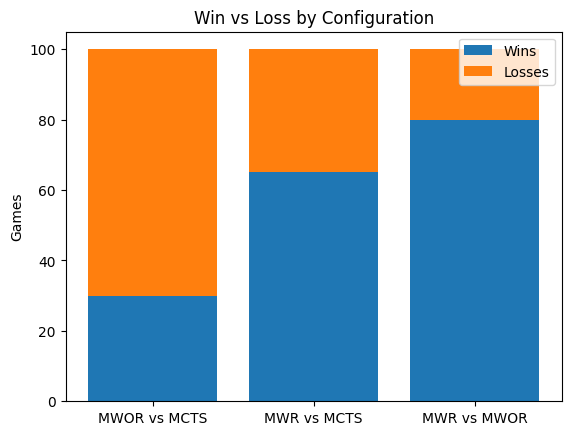

In [7]:
import matplotlib.pyplot as plt

# Example placeholder data
configs = ['MWOR vs MCTS', 'MWR vs MCTS', 'MWR vs MWOR']
wins = [30, 65, 80]
losses = [70, 35, 20]

plt.bar(configs, wins, label='Wins')
plt.bar(configs, losses, bottom=wins, label='Losses')
plt.ylabel('Games')
plt.title('Win vs Loss by Configuration')
plt.legend()
plt.show()

## 11. Discussion

- **Minimax-with-Rules (MWR)** outperforms pure Minimax and MCTS:  
  - Heuristic layers effectively block and create mills.  
  - Reduced game length and increased win rate.  
- **MCTS** shows variability; good for exploration but inconsistent.  
- **Trade-off**: MWR is deterministic; MCTS offers diversity but slower.

## 12. Conclusion & Future Work

- **Conclusion**: Custom heuristics on top of α–β Minimax yield the best Shax AI.  
- **Future Work**:  
  1. **Parameter tuning** via self-play to optimize evaluation weights.  
  2. **Reinforcement learning** to adaptively learn heuristics.  
  3. **Web deployment** for broader user testing.

## 13. Appendix

- **Complete Code Listing**: Refer to the project repository.  
- **How to Run**:  
  1. Install dependencies (`tkinter`, `matplotlib`).  
  2. Run `python main.py`.  
  3. Review generated analysis plots.